### User Clarification and Brief Generation
The goal of scoping is to gather user-context needed for research.

Here is our overall research flow:

![scope_workflow](../notebook_images/scoping_workflow.png)

### Scope the research in two phases:

- User Clarification - Determines if additional clarification is needed from the user
- Brief Generation - Transforms the conversation into a detailed research brief


In [193]:
import os 
from dotenv import load_dotenv
load_dotenv()

# Disable deprecated LangChain v1 tracer if present
os.environ.pop("LANGCHAIN_TRACING", None)

# Enable LangChain tracing v2 (optional; no-op without API key)
os.environ["LANGCHAIN_TRACING_V2"] = os.getenv("LANGCHAIN_TRACING_V2", "true")

# Set GROQ key from environment
os.environ["GROQ_API_KEY"] = groq_api_key = os.getenv("GROQ_API_KEY")


In [194]:
## Prompt 
clarify_with_user_instructions="""
These are the messages that have been exchanged so far from the user asking for the report:
<Messages>
{messages}
</Messages>

Today's date is {date}.

Assess whether you need to ask a clarifying question, or if the user has already provided enough information for you to start research.
IMPORTANT: If you can see in the messages history that you have already asked a clarifying question, you almost always do not need to ask another one. Only ask another question if ABSOLUTELY NECESSARY.

If there are acronyms, abbreviations, or unknown terms, ask the user to clarify.
If you need to ask a question, follow these guidelines:
- Be concise while gathering all necessary information
- Make sure to gather all the information needed to carry out the research task in a concise, well-structured manner.
- Use bullet points or numbered lists if appropriate for clarity. Make sure that this uses markdown formatting and will be rendered correctly if the string output is passed to a markdown renderer.
- Don't ask for unnecessary information, or information that the user has already provided. If you can see that the user has already provided the information, do not ask for it again.

Respond in valid JSON format with these exact keys:
"need_clarification": boolean,
"question": "<question to ask the user to clarify the report scope>",
"verification": "<verification message that we will start research>"

If you need to ask a clarifying question, return:
"need_clarification": true,
"question": "<your clarifying question>",
"verification": ""

If you do not need to ask a clarifying question, return:
"need_clarification": false,
"question": "",
"verification": "<acknowledgement message that you will now start research based on the provided information>"

For the verification message when no clarification is needed:
- Acknowledge that you have sufficient information to proceed
- Briefly summarize the key aspects of what you understand from their request
- Confirm that you will now begin the research process
- Keep the message concise and professional
"""

In [195]:
transform_messages_into_research_topic_prompt = """You will be given a set of messages that have been exchanged so far between yourself and the user. 
Your job is to translate these messages into a more detailed and concrete research question that will be used to guide the research.

The messages that have been exchanged so far between yourself and the user are:
<Messages>
{messages}
</Messages>

Today's date is {date}.

You will return a single research question that will be used to guide the research.

Guidelines:
1. Maximize Specificity and Detail
- Include all known user preferences and explicitly list key attributes or dimensions to consider.
- It is important that all details from the user are included in the instructions.

2. Handle Unstated Dimensions Carefully
- When research quality requires considering additional dimensions that the user hasn't specified, acknowledge them as open considerations rather than assumed preferences.
- Example: Instead of assuming "budget-friendly options," say "consider all price ranges unless cost constraints are specified."
- Only mention dimensions that are genuinely necessary for comprehensive research in that domain.

3. Avoid Unwarranted Assumptions
- Never invent specific user preferences, constraints, or requirements that weren't stated.
- If the user hasn't provided a particular detail, explicitly note this lack of specification.
- Guide the researcher to treat unspecified aspects as flexible rather than making assumptions.

4. Distinguish Between Research Scope and User Preferences
- Research scope: What topics/dimensions should be investigated (can be broader than user's explicit mentions)
- User preferences: Specific constraints, requirements, or preferences (must only include what user stated)
- Example: "Research coffee quality factors (including bean sourcing, roasting methods, brewing techniques) for San Francisco coffee shops, with primary focus on taste as specified by the user."

5. Use the First Person
- Phrase the request from the perspective of the user.

6. Sources
- If specific sources should be prioritized, specify them in the research question.
- For product and travel research, prefer linking directly to official or primary websites (e.g., official brand sites, manufacturer pages, or reputable e-commerce platforms like Amazon for user reviews) rather than aggregator sites or SEO-heavy blogs.
- For academic or scientific queries, prefer linking directly to the original paper or official journal publication rather than survey papers or secondary summaries.
- For people, try linking directly to their LinkedIn profile, or their personal website if they have one.
- If the query is in a specific language, prioritize sources published in that language.
"""

### State and Schemas

In [196]:
import operator 
from typing_extensions import TypedDict 
from typing import Annotated , List , Sequence , Optional 

from langchain_core.messages import BaseMessage 
from langgraph.graph.message import  add_messages
from langgraph.graph import MessagesState
from pydantic import BaseModel , Field 

In [197]:
class AgentInputState(MessagesState):
    """Input state for the full agent - only contains messages from user input."""
    pass


In [198]:
class AgentState(MessagesState) : 
    """
    Main State for the multi -agent system. 
    """

    # Research brief generate from the user conversation history 
    research_brief : Optional[str]
    # Messages exchanged with the supervisor agent for coordination
    supervisor_messages : Annotated[Sequence[BaseMessage] , add_messages]
    # Raw unprocessed research notes collected during the research phase
    raw_notes : Annotated[List[str] , operator.add] = []
    # Processed and structured notes ready for report generation
    notes : Annotated[List[str] , operator.add] = []
    # Final formatted research report
    final_report = str 
    

In [199]:
class ClarifyWithUser(BaseModel) : 
    need_clarification : bool = Field(description="whether the user needs to be asked a clarifying question.")
    question : str = Field(description= "A question to ask the user to clarify the report scope.")
    verification : str = Field(description="Verify message that we will start research after the user has provided the necessary information.")

class ResearchQuestion(BaseModel) :
    research_brief : str = Field(description="A research question that will be used to guide the research.")

### Scope Research 

create a simple workflow to clarify the user's intent and write a research brief.

In [200]:
from datetime import datetime
from typing_extensions import Literal

from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage , AIMessage , get_buffer_string
from langgraph.graph import START,  END , StateGraph 
from langgraph.types import Command 


In [201]:
def get_today_str() -> str : 
    """Get current date in a human-readable format, cross-platform."""
    dt = datetime.now()
    return f"{dt.strftime('%a %b')} {dt.day}, {dt.strftime('%Y')}"


In [202]:
model = ChatGroq(model="openai/gpt-oss-120b")

model.invoke("Hello")

AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "Hello". We need to respond appropriately. No special instructions. Just greet back.'}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 72, 'total_tokens': 111, 'completion_time': 0.080209759, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.002800482, 'prompt_tokens_details': None, 'queue_time': 0.050176378, 'total_time': 0.083010241}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4a19b1544c', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019b6434-e3a3-7e92-95e3-c668bf7234a7-0', usage_metadata={'input_tokens': 72, 'output_tokens': 39, 'total_tokens': 111, 'output_token_details': {'reasoning': 21}})

In [203]:
## Nodes 

def clarify_with_user(state: AgentState) -> Command[Literal["write_research_brief", "__end__"]]:
    """
    Determine if the user's request contains sufficient information to proceed with research.
    """

    structured_output_model = model.with_structured_output(ClarifyWithUser, method="json_schema")

    response = structured_output_model.invoke(
        [
            HumanMessage(content=clarify_with_user_instructions.format(
                messages = get_buffer_string(messages=state['messages']) ,
                date = get_today_str()
            ))
        ]
    )

    # Route based on clarification 
    if response.need_clarification :
        return Command(
            goto = END ,
            update={"messages" : [AIMessage(content=response.question)]}
        )
    
    else : 
        return Command (
            goto = 'write_research_brief' ,
            update={"messages" : [AIMessage(content = response.verification)]}
        )


In [204]:
def write_research_brief(state:AgentState) : 
    """ Transform the conversation history into a comprehensive research brief. """

    structured_output_model = model.with_structured_output(ResearchQuestion, method="json_schema")

    response = structured_output_model.invoke(
        [
            HumanMessage(content=transform_messages_into_research_topic_prompt.format(
                messages = get_buffer_string(messages=state.get('messages', [])) ,
                date = get_today_str()
            ))
        ]
    )

    return {
        "research_brief" : response.research_brief ,
        "supervisor_messages" : [HumanMessage(content=f"{response.research_brief}.")]
    }


In [205]:
from IPython.display import Image , display 
from langgraph.checkpoint.memory import InMemorySaver 

checkpointer = InMemorySaver()

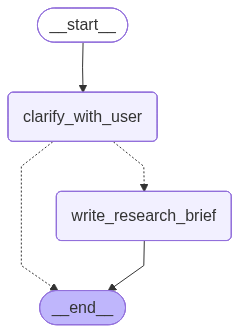

In [206]:
# Build Graph 

deep_researcher_builder  = StateGraph(AgentState , input_schema=AgentInputState)

deep_researcher_builder.add_node("clarify_with_user" , clarify_with_user)
deep_researcher_builder.add_node("write_research_brief" , write_research_brief)

deep_researcher_builder.add_edge(START , "clarify_with_user")
deep_researcher_builder.add_edge("clarify_with_user" , END)
deep_researcher_builder.add_edge("write_research_brief" , END)

scope_research  = deep_researcher_builder.compile(checkpointer=checkpointer)

display(Image(scope_research.get_graph().draw_mermaid_png()))

In [207]:
# Run the workflow 

from pprint import PrettyPrinter
thread = {'configurable' : {"thread_id" : "1"}}
result = scope_research.invoke({"messages": [HumanMessage(content="I want to research the best coffee shops in Tokyo.")]}, config=thread)

for msg in result.get('messages', []):
    msg.pretty_print()
    

================================ Human Message =================================

I want to research the best coffee shops in Tokyo.
================================== Ai Message ==================================

Got it. You’d like a report on the best coffee shops in Tokyo. I will now begin researching and compiling the information.


In [208]:
result = scope_research.invoke({"messages": [HumanMessage(content="Let's examine coffee quality to assess the best coffee shops in Tokyo.")]}, config=thread)

for msg in result.get('messages', []):
    msg.pretty_print()

================================ Human Message =================================

I want to research the best coffee shops in Tokyo.
================================== Ai Message ==================================

Got it. You’d like a report on the best coffee shops in Tokyo. I will now begin researching and compiling the information.
================================ Human Message =================================

Let's examine coffee quality to assess the best coffee shops in Tokyo.
================================== Ai Message ==================================

I have enough information: you want a report on the best coffee shops in Tokyo, focusing on coffee quality. I will now begin researching and compiling the findings.


In [209]:
from IPython.display import Markdown

Markdown(result['research_brief'])

I want to identify the best coffee shops in Tokyo based on coffee quality, evaluating factors such as bean origin, roast level, brewing method, taste profile, and consistency, while considering all price ranges and locations since no specific constraints were provided.

### Evaluation

what makes for a good research brief:

- It captures relevant criteria from the user chat
- It does not invent or assume any criteria that the user did not explicitly provide

In [210]:
from langchain_core.messages import AIMessage

conversation_1 = [
    HumanMessage(content="What's the best way to invest $50,000 for retirement?"),
    AIMessage(content="Could you please provide some additional information to tailor the investment advice for your $50,000 retirement goal? Specifically:\n Your current age or desired retirement age\n Your risk tolerance (low, medium, high)\n Any preferences for investment types (e.g., stocks, bonds, mutual funds, real estate)\n Whether you are investing through a tax-advantaged account (e.g., IRA, 401(k)) or a regular brokerage account\n This will help me provide more personalized and relevant suggestions."),
    HumanMessage(content="I'm 25 and I want to retire by 45. My risk tolerance is high right now but I think will decrease over time. I have heard that stocks and ETFs are a good choice, but I'm open to anything. And I already have a 401k, but this would just be through a regular brokerage account."),
]

conversation_2 = [
    HumanMessage(content="I am looking for an apartment in NYC, can you help me?"),
    AIMessage(content="Could you please specify your apartment preferences? For example:\n Desired neighborhoods or boroughs\n Number of bedrooms/bathrooms\n Budget range (monthly rent)\n Any amenities or must-have features\n Preferred move-in date\n This information will help me provide the most relevant apartment options in NYC."),
    HumanMessage(content="I'd prefer to live in Chelsea, Flatiron, or West Village. I'm looking for a 2 bed 2 bath, and I am looking for monthly rent below 7k. I'd like this to be a doorman building and have an in unit washer and dryer, but it's okay if there's no washer dryer. It's a plus if the building has a gym. And I'd like to move in in September 2025."),
]

In [211]:
criteria_1 = [
    "Current age is 25",
    "Desired retirement age is 45",
    "Current risk tolerance is high",
    "Interested in investing in stocks and ETFs",
    "Open to forms of investment beyond stocks and ETFs"
    "Investment account is a regular brokerage account",
]

criteria_2 = [
    "Looking for a 2 bed 2 bath apartment in Chelsea, Flatiron, or West Village",
    "Monthly rent below 7k",
    "Should be in a doorman building",
    "Ideally have an in unit washer and dryer but not strict",
    "Ideally have a gym but not strict",
    "Move in date is September 2025"
]

### Running an experiment in LangSmith comprises of three steps:

1. Creating the dataset
2. Writing the evaluator(s)
3. Running the experiment

The flow will look like this:

![flow](../notebook_images/scoping_evaluation.png)

In [212]:
from langsmith import Client
langsmith_client = Client(api_key=os.getenv("LANGCHAIN_API_KEY"))

# Create the dataset
dataset_name = "deep_research_scoping"
if not langsmith_client.has_dataset(dataset_name=dataset_name):
    
    # Create the dataset
    dataset = langsmith_client.create_dataset(
        dataset_name=dataset_name,
        description="A dataset that measures the quality of research briefs generated from an input conversation",
    )

    # Add the examples to the dataset
    langsmith_client.create_examples(
        dataset_id=dataset.id,
        examples=[
            {
                "inputs": {"messages": conversation_1},
                "outputs": {"criteria": criteria_1},
            },
            {
                "inputs": {"messages": conversation_2},
                "outputs": {"criteria": criteria_2},
            },
        ],
    )

In [213]:
BRIEF_CRITERIA_PROMPT = """
<role>
You are an expert research brief evaluator specializing in assessing whether generated research briefs accurately capture user-specified criteria without loss of important details.
</role>

<task>
Determine if the research brief adequately captures the specific success criterion provided. Return a binary assessment with detailed reasoning.
</task>

<evaluation_context>
Research briefs are critical for guiding downstream research agents. Missing or inadequately captured criteria can lead to incomplete research that fails to address user needs. Accurate evaluation ensures research quality and user satisfaction.
</evaluation_context>

<criterion_to_evaluate>
{criterion}
</criterion_to_evaluate>

<research_brief>
{research_brief}
</research_brief>

<evaluation_guidelines>
CAPTURED (criterion is adequately represented) if:
- The research brief explicitly mentions or directly addresses the criterion
- The brief contains equivalent language or concepts that clearly cover the criterion
- The criterion's intent is preserved even if worded differently
- All key aspects of the criterion are represented in the brief

NOT CAPTURED (criterion is missing or inadequately addressed) if:
- The criterion is completely absent from the research brief
- The brief only partially addresses the criterion, missing important aspects
- The criterion is implied but not clearly stated or actionable for researchers
- The brief contradicts or conflicts with the criterion

<evaluation_examples>
Example 1 - CAPTURED:
Criterion: "Current age is 25"
Brief: "...investment advice for a 25-year-old investor..."
Judgment: CAPTURED - age is explicitly mentioned

Example 2 - NOT CAPTURED:
Criterion: "Monthly rent below 7k"
Brief: "...find apartments in Manhattan with good amenities..."
Judgment: NOT CAPTURED - budget constraint is completely missing

Example 3 - CAPTURED:
Criterion: "High risk tolerance"
Brief: "...willing to accept significant market volatility for higher returns..."
Judgment: CAPTURED - equivalent concept expressed differently

Example 4 - NOT CAPTURED:
Criterion: "Doorman building required"
Brief: "...find apartments with modern amenities..."
Judgment: NOT CAPTURED - specific doorman requirement not mentioned
</evaluation_examples>
</evaluation_guidelines>

<output_instructions>
1. Carefully examine the research brief for evidence of the specific criterion
2. Look for both explicit mentions and equivalent concepts
3. Provide specific quotes or references from the brief as evidence
4. Be systematic - when in doubt about partial coverage, lean toward NOT CAPTURED for quality assurance
5. Focus on whether a researcher could act on this criterion based on the brief alone
</output_instructions>"""


In [214]:
from typing_extensions import cast
from pydantic import BaseModel , Field 
from langchain_groq import ChatGroq 

class Criteria(BaseModel):
    """
    Individual success criteria evaluation result.
    
    This model represents a single evaluation criteria that should be present
    in the research brief, along with a detailed assessment of whether it was
    successfully captured and the reasoning behind that assessment.
    """
    criteria_text: str = Field(
        description="The specific success criteria being evaluated (e.g., 'Current age is 25', 'Monthly rent below 7k')"
    )
    reasoning: str = Field(
        description="Detailed explanation of why this criteria is or isn't captured in the research brief, including specific evidence from the brief"
    )
    is_captured: bool = Field(
        description="Whether this specific criteria is adequately captured in the research brief (True) or missing/inadequately addressed (False)"
    )

In [215]:
def evaluate_success_criteria(outputs: dict, reference_outputs: dict):
    """
    Evaluate whether the research brief captures all required success criteria.
    
    This function evaluates each criterion individually to provide focused assessment
    and detailed reasoning for each evaluation decision.
    
    Args:
        outputs: Dictionary containing the research brief to evaluate
        reference_outputs: Dictionary containing the list of success criteria
        
    Returns:
        Dict with evaluation results including score (0.0 to 1.0)
    """
    import time
    try:
        from groq import RateLimitError
    except Exception:
        class RateLimitError(Exception):
            pass

    research_brief = outputs["research_brief"]
    success_criteria = reference_outputs["criteria"]

    model = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
    
    # Use JSON schema structured output to avoid tool-calling requirements
    structured_output_model = model.with_structured_output(Criteria, method="json_schema")
    
    # Run evals sequentially with simple backoff to mitigate TPM rate limits
    responses = []
    for criterion in success_criteria:
        prompt = BRIEF_CRITERIA_PROMPT.format(
            research_brief=research_brief,
            criterion=criterion
        )
        attempt = 0
        while True:
            try:
                resp = structured_output_model.invoke(
                    [HumanMessage(content=prompt)],
                    max_completion_tokens=256,
                )
                responses.append(resp)
                break
            except RateLimitError:
                attempt += 1
                if attempt > 3:
                    raise
                time.sleep(0.75 * attempt)
            except Exception:
                # brief fallback retry for transient network/model errors
                attempt += 1
                if attempt > 2:
                    raise
                time.sleep(0.5 * attempt)
    
    # Ensure the criteria_text field is populated correctly
    individual_evaluations = [
        Criteria(
            reasoning=response.reasoning,
            criteria_text=criterion,
            is_captured=response.is_captured
        )
        for criterion, response in zip(success_criteria, responses)
    ]
    
    # Calculate overall score as percentage of captured criteria
    captured_count = sum(1 for eval_result in individual_evaluations if eval_result.is_captured)
    total_count = len(individual_evaluations)
    
    return {
        "key": "success_criteria_score", 
        "score": captured_count / total_count if total_count > 0 else 0.0,
        "individual_evaluations": [
            {
                "criteria": eval_result.criteria_text,
                "captured": eval_result.is_captured,
                "reasoning": eval_result.reasoning
            }
            for eval_result in individual_evaluations
        ],
    }


In [216]:
BRIEF_HALLUCINATION_PROMPT = """
## Brief Hallucination Evaluator

<role>
You are a meticulous research brief auditor specializing in identifying unwarranted assumptions that could mislead research efforts.
</role>

<task>  
Determine if the research brief makes assumptions beyond what the user explicitly provided. Return a binary pass/fail judgment.
</task>

<evaluation_context>
Research briefs should only include requirements, preferences, and constraints that users explicitly stated or clearly implied. Adding assumptions can lead to research that misses the user's actual needs.
</evaluation_context>

<research_brief>
{research_brief}
</research_brief>

<success_criteria>
{success_criteria}
</success_criteria>

<evaluation_guidelines>
PASS (no unwarranted assumptions) if:
- Brief only includes explicitly stated user requirements
- Any inferences are clearly marked as such or logically necessary
- Source suggestions are general recommendations, not specific assumptions
- Brief stays within the scope of what the user actually requested

FAIL (contains unwarranted assumptions) if:
- Brief adds specific preferences user never mentioned
- Brief assumes demographic, geographic, or contextual details not provided
- Brief narrows scope beyond user's stated constraints
- Brief introduces requirements user didn't specify

<evaluation_examples>
Example 1 - PASS:
User criteria: ["Looking for coffee shops", "In San Francisco"] 
Brief: "...research coffee shops in San Francisco area..."
Judgment: PASS - stays within stated scope

Example 2 - FAIL:
User criteria: ["Looking for coffee shops", "In San Francisco"]
Brief: "...research trendy coffee shops for young professionals in San Francisco..."
Judgment: FAIL - assumes "trendy" and "young professionals" demographics

Example 3 - PASS:
User criteria: ["Budget under $3000", "2 bedroom apartment"]
Brief: "...find 2-bedroom apartments within $3000 budget, consulting rental sites and local listings..."
Judgment: PASS - source suggestions are appropriate, no preference assumptions

Example 4 - FAIL:
User criteria: ["Budget under $3000", "2 bedroom apartment"] 
Brief: "...find modern 2-bedroom apartments under $3000 in safe neighborhoods with good schools..."
Judgment: FAIL - assumes "modern", "safe", and "good schools" preferences
</evaluation_examples>
</evaluation_guidelines>

<output_instructions>
Carefully scan the brief for any details not explicitly provided by the user. Be strict - when in doubt about whether something was user-specified, lean toward FAIL.
</output_instructions>"""

In [217]:
class NoAssumptions(BaseModel):
    """
    Evaluation model for checking if research brief makes unwarranted assumptions.
    """
    no_assumptions: bool = Field(
        description="Whether the research brief avoids making unwarranted assumptions. True if the brief only includes information explicitly provided by the user, False if it makes assumptions beyond what was stated."
    )
    reasoning: str = Field(
        description="Detailed explanation of the evaluation decision, including specific examples of any assumptions found or confirmation that no assumptions were made beyond the user's explicit statements."
    )


def evaluate_no_assumptions(outputs: dict, reference_outputs: dict):
    """
    Evaluate whether the research brief avoids making unwarranted assumptions.
    
    This evaluator checks that the research brief only includes information
    and requirements that were explicitly provided by the user, without
    making assumptions about unstated preferences or requirements.
    
    Args:
        outputs: Dictionary containing the research brief to evaluate
        reference_outputs: Dictionary containing the success criteria for reference
        
    Returns:
        Dict with evaluation results including boolean score and detailed reasoning
    """
    research_brief = outputs["research_brief"]
    success_criteria = reference_outputs["criteria"]
    
    model = ChatGroq(model="openai/gpt-oss-120b", temperature=0)

    # Use JSON schema structured output to avoid tool-calling requirements
    structured_output_model = model.with_structured_output(NoAssumptions, method="json_schema")
    
    response = structured_output_model.invoke([
        HumanMessage(content=BRIEF_HALLUCINATION_PROMPT.format(
            research_brief=research_brief, 
            success_criteria=str(success_criteria)
        ))
    ], max_completion_tokens=256)
    
    return {
        "key": "no_assumptions_score", 
        "score": response.no_assumptions,
        "reasoning": response.reasoning
    }


In [ ]:
import uuid

def target_func(inputs: dict):
    config = {"configurable": {"thread_id": uuid.uuid4()}}
    return scope_research.invoke(inputs, config=config)

langsmith_client.evaluate(
    target_func,
    data=dataset_name,
    evaluators=[evaluate_success_criteria, evaluate_no_assumptions],
    experiment_prefix="Deep Research Scoping",
)

### Why perform evals like this?

- Ensure that individual steps in  application are doing what we expect.
- With tracing to LangSmith, we also get a sense of how long each step takes as well as the cost.
- we can always try out cheaper, faster models to see if they can get the job done.